In [2]:
%%html
<span class="cosi-notebook-theme" style="display:none;"></span>

<style>
/* =====================================================
   JupyterLab Markdown Heading Theme
   Original design restored — H1 to H4
   ===================================================== */

/* H1 — Deep Blue → Bright Blue Gradient */
.jp-Notebook:has(.cosi-notebook-theme) .jp-RenderedMarkdown h1 {
    background: linear-gradient(90deg, #1e3a8a, #3b82f6);
    color: #ffffff;
    padding: 20px 25px;
    border-radius: 8px;
    margin-top: 30px;
    margin-bottom: 18px;
    font-weight: 700;
}

/* H2 — Light Blue Background + Blue Left Border */
.jp-Notebook:has(.cosi-notebook-theme) .jp-RenderedMarkdown h2 {
    background-color: #eff6ff;
    color: #1e40af;
    border-left: 6px solid #2563eb;
    padding: 12px 16px;
    border-radius: 5px;
    margin-top: 24px;
    margin-bottom: 14px;
    font-weight: 650;
}

/* H3 — Teal Text + Bottom Border */
.jp-Notebook:has(.cosi-notebook-theme) .jp-RenderedMarkdown h3 {
    color: #0f766e;
    border-bottom: 2px solid #99f6e4;
    padding: 7px 4px;
    margin-top: 20px;
    margin-bottom: 12px;
    font-weight: 600;
}

/* H4 — Slate Text + Subtle Left Border */
.jp-Notebook:has(.cosi-notebook-theme) .jp-RenderedMarkdown h4 {
    color: #475569;
    border-left: 3px solid #94a3b8;
    padding: 5px 10px;
    margin-top: 16px;
    margin-bottom: 10px;
    font-weight: 600;
}
</style>


# Imports and Preparation

In [3]:
# Standard library
import logging
from datetime import date
from pathlib import Path

# Third-party packages
import astropy.units as u
from astropy.coordinates import SkyCoord

# Photozpy
from photozpy import (
    Artifacts,
    Combine,
    HeaderCorrection,
    ImageCollectionGroup,
    ImageReviewer,
    PlateSolving,
    Reduction,
    Registration,
)
from photozpy.collections.image_collection_helpers import (
    refresh_image_collection_group,
)
from photozpy.photometry.fwhm import FWHM
from photozpy.photometry.photometry import Photometry
from photozpy.photometry.regions import (
    PhotometryRegionCollection,
    PhotometryRegions,
)
from photozpy.sources import ObservationField, SourceInfo, Sources
from photozpy.standard_stars import StandardStarCatalog
from photozpy.telescope import SARA_CT


# Logging configuration
logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s: %(message)s",
)
logging.getLogger("photozpy").setLevel(logging.INFO)

## Check the telescope

### Check CCD

In [4]:

SARA_CT.print_ccd_summary()

╒════════════════════╤════════════════════╕
│ field              │ value              │
╞════════════════════╪════════════════════╡
│ name               │ CT Andor Ikon-L    │
├────────────────────┼────────────────────┤
│ gain               │ 1.0 electron / adu │
├────────────────────┼────────────────────┤
│ rdnoise            │ 7.1 electron / pix │
├────────────────────┼────────────────────┤
│ valid_from         │ 2021-01-01         │
├────────────────────┼────────────────────┤
│ valid_to           │ 9999-12-31         │
├────────────────────┼────────────────────┤
│ native_pixel_scale │ 0.34 arcsec / pix  │
├────────────────────┼────────────────────┤
│ nx                 │                    │
├────────────────────┼────────────────────┤
│ ny                 │                    │
├────────────────────┼────────────────────┤
│ saturation         │                    │
├────────────────────┼────────────────────┤
│ full_well          │                    │
├────────────────────┼──────────

### Check Filters

In [5]:
SARA_CT.print_filterset_summary()

╒═════════════════════════╤═══════════════════════════════════════════════════════════╕
│ Standard Filter Names   │ Alias                                                     │
╞═════════════════════════╪═══════════════════════════════════════════════════════════╡
│ SDSS_u'                 │ ("Sloan u'2", 'SDSS u', "Sloan_u'2", 'SDSS_u', 'SDSS_up') │
├─────────────────────────┼───────────────────────────────────────────────────────────┤
│ SDSS_g'                 │ ("Sloan g'2", 'SDSS g', "Sloan_g'2", 'SDSS_g', 'SDSS_gp') │
├─────────────────────────┼───────────────────────────────────────────────────────────┤
│ SDSS_r'                 │ ("Sloan r'2", 'SDSS r', "Sloan_r'2", 'SDSS_r', 'SDSS_rp') │
├─────────────────────────┼───────────────────────────────────────────────────────────┤
│ SDSS_i'                 │ ("Sloan i'2", 'SDSS i', "Sloan_i'2", 'SDSS_i', 'SDSS_ip') │
├─────────────────────────┼───────────────────────────────────────────────────────────┤
│ SDSS_z'                 │ ("Sl

## Define Sources Observed

### First, let's define observation fields

In [6]:
FGL_field = ObservationField(
    field_name="fgl_field",
    telescope=SARA_CT,
    nominal_pointing=SkyCoord(
        ra="07:46:42.30",
        dec="-47:54:55.28",
        frame="icrs",
        unit=(u.hourangle, u.deg),
    ),
    file_pattern="4FGL_J0746_",
)

In [7]:
SUMSS_field = ObservationField(
    field_name="SUMSS_field",
    telescope=SARA_CT,
    nominal_pointing=SkyCoord(
        ra="07:56:24.60",
        dec="-64:30:30.52",
        frame="icrs",
        unit=(u.hourangle, u.deg),
    ),
    file_pattern="SUMSS",
)

In [8]:
DLS_field = ObservationField(
    field_name="DLS_field",
    telescope=SARA_CT,
    nominal_pointing=SkyCoord(
        ra=" 10:52:00",
        dec="-05:00:00",
        frame="icrs",
        unit=(u.hourangle, u.deg),
    ),
    file_pattern="DLS",
)

### Next, let's define sources in each observation field

In [9]:
fgl_J0746 = SourceInfo(
    source_name="4FGL J0746.6-4754",
    source_role="science",
    source_coordinate=SkyCoord(
        ra="07:46:42.30",
        dec="-47:54:55.28",
        frame="icrs",
        unit=(u.hourangle, u.deg),
    ),
    observation_field=FGL_field,
)

In [10]:
sumss_J0756 = SourceInfo(
    source_name="SUMSS J075625-643031",
    source_role="science",
    source_coordinate=SkyCoord(
        ra="07:56:24.60",
        dec="-64:30:30.52",
        frame="icrs",
        unit=(u.hourangle, u.deg),
    ),
    observation_field=SUMSS_field,
)

<!-- NOTE -->
<div style="background-color:#e7f3ff; border-left:4px solid #2196f3; padding:12px 16px; border-radius:4px; margin:12px 0;">
  <strong>📝 Note: How about standard stars?</strong>
  <p>There is no need to create standard sources yet. They will be created automatically after standard searching.</p>
</div>

In [11]:
sources = Sources(fgl_J0746, sumss_J0756)

In [12]:
sources[1]

Sources(
  source_name='SUMSS J075625-643031',
  coordinates (ICRS): 07:56:24.60 -64:30:30.52,
  magnitudes: instrumental=undefined, reference=undefined, calibrated=undefined
)

# Create Image File Collection 

In [14]:
data_root_dir = Path("/Users/yong/Desktop/Research/Photozpy/photozpy_packages/refactoring/Demostration_副本")

raw_image_collection = ImageCollectionGroup(
    directories=data_root_dir,
)

In [13]:
# # For restart analysis

# analysis_dir = data_root_dir / "analysis"

# analysis_images = ImageCollectionGroup(
#     directories=analysis_dir,
# )

# Examine Image Quality

In [15]:
# Get the image list
review_images = [
    Path(filename)
    for collection in raw_image_collection
    for filename in collection.files_filtered(include_path=True)
]

In [16]:
# Start a reviewer
reviewer = ImageReviewer(
    images=review_images,
    rejected_dir=data_root_dir / "rejected",
    isolated=True,
)

rejected_images = reviewer.run()

print(f"Reviewed: {reviewer.index}/{len(review_images)}")
print(f"Rejected: {len(rejected_images)}")

# Refresh the raw collection after rejected files have been moved.
refresh_image_collection_group(raw_image_collection)

Reviewed: 255/255
Rejected: 2


# Calibration

## Update Fits Headers

In [17]:
analysis_dir = data_root_dir / "analysis"

headers = HeaderCorrection(
    image_collection=raw_image_collection,
    observation_fields=(FGL_field, SUMSS_field, DLS_field),
    save_location=analysis_dir,
    overwrite=False,
)

In [18]:
# Standardize IMTYPE; add FIELD for light frames; update GAIN, RDNOISE,
# and BUNIT; compute MJD-OBS using DATE-OBS and TIMESYS.
# Fill missing RA/DEC from nominal field pointing; preserve OBJECT.
# Save the working copies in analysis/.
analysis_images: ImageCollectionGroup = headers.correct_headers_by_filename()

Updating FITS headers:   0%|          | 0/253 [00:00<?, ?file/s]

In [19]:
# Standardize FILTER names for Flat and Light frames using telescope aliases.
# Update the working copies in analysis/; leave other frames unchanged.
analysis_images: ImageCollectionGroup = headers.correct_filter_headers(overwrite=True)

Updating FITS headers:   0%|          | 0/253 [00:00<?, ?file/s]

## Bias Correction

In [20]:
# Build the master bias and return the updated image collection.

combiner: Combine = Combine(
    image_collection=analysis_images,
    telescope=SARA_CT,
)

analysis_images: ImageCollectionGroup = combiner.combine_bias_or_dark(
    image_type="Bias",
)

INFO: Bias
----------------------------------------------------------------
Combining 30 Bias frames → Master_Bias.fits
Input files:
  Bias_001.fits, Bias_002.fits, Bias_003.fits, Bias_004.fits, Bias_005.fits,
  Bias_006.fits, Bias_007.fits, Bias_008.fits, Bias_009.fits, Bias_010.fits,
  Bias_011.fits, Bias_012.fits, Bias_013.fits, Bias_014.fits, Bias_015.fits,
  Bias_016.fits, Bias_017.fits, Bias_018.fits, Bias_019.fits, Bias_020.fits,
  Bias_021.fits, Bias_022.fits, Bias_023.fits, Bias_024.fits, Bias_025.fits,
  Bias_026.fits, Bias_027.fits, Bias_028.fits, Bias_029.fits, Bias_030.fits
INFO: Master written successfully.



In [21]:
# Subtract bias and return the updated image collection.
# Update BIASCORR='Yes' in the working images.

reducer: Reduction = Reduction(
    image_collection=analysis_images,
    telescope=SARA_CT,
    overwrite=True,
)

analysis_images = reducer.apply_bias_correction()

Bias correction:   0%|          | 0/223 [00:00<?, ?image/s]

## Dark Correction

In [22]:
# Build the master dark and return the updated image collection.

combiner: Combine = Combine(
    image_collection=analysis_images,
    telescope=SARA_CT,
)

analysis_images: ImageCollectionGroup = combiner.combine_bias_or_dark(
    image_type="Dark",
)

INFO: Dark
----------------------------------------------------------------
Combining 30 Dark frames → Master_Dark.fits
Input files:
  Dark_001.fits, Dark_002.fits, Dark_003.fits, Dark_004.fits, Dark_005.fits,
  Dark_006.fits, Dark_007.fits, Dark_008.fits, Dark_009.fits, Dark_010.fits,
  Dark_011.fits, Dark_012.fits, Dark_013.fits, Dark_014.fits, Dark_015.fits,
  Dark_016.fits, Dark_017.fits, Dark_018.fits, Dark_019.fits, Dark_020.fits,
  Dark_021.fits, Dark_022.fits, Dark_023.fits, Dark_024.fits, Dark_025.fits,
  Dark_026.fits, Dark_027.fits, Dark_028.fits, Dark_029.fits, Dark_030.fits
INFO: Master written successfully.



In [23]:
# Subtract the exposure-scaled master dark from Flat and Light frames.
# Update DARKCORR='Yes' in the working images.

reducer: Reduction = Reduction(
    image_collection=analysis_images,
    telescope=SARA_CT,
    overwrite=True,
)

analysis_images = reducer.apply_dark_correction()

Dark correction:   0%|          | 0/193 [00:00<?, ?image/s]

## Flat Correction

In [24]:
# Build one master flat per FILTER.
# Scale individual flats by their inverse median before combining.

combiner: Combine = Combine(
    image_collection=analysis_images,
    telescope=SARA_CT,
)

analysis_images = combiner.combine_light_or_flat(
    image_type="Flat",
)

INFO: Flat | FILTER=SDSS_g'
----------------------------------------------------------------
Combining 12 Flat frames → Master_Flat_SDSS_g'.fits
Input files:
  Flat_SDSS_g_005.fits, Flat_SDSS_g_006.fits, Flat_SDSS_g_009.fits,
  Flat_SDSS_g_010.fits, Flat_SDSS_g_014.fits, Flat_SDSS_g_017.fits,
  Flat_SDSS_g_020.fits, Flat_SDSS_g_023.fits, Flat_SDSS_g_026.fits,
  Flat_SDSS_g_029.fits, Flat_SDSS_g_032.fits, Flat_SDSS_g_035.fits
INFO: Master written successfully.

INFO: Flat | FILTER=SDSS_i'
----------------------------------------------------------------
Combining 12 Flat frames → Master_Flat_SDSS_i'.fits
Input files:
  Flat_SDSS_i_004.fits, Flat_SDSS_i_008.fits, Flat_SDSS_i_012.fits,
  Flat_SDSS_i_013.fits, Flat_SDSS_i_016.fits, Flat_SDSS_i_019.fits,
  Flat_SDSS_i_022.fits, Flat_SDSS_i_025.fits, Flat_SDSS_i_028.fits,
  Flat_SDSS_i_031.fits, Flat_SDSS_i_034.fits, Flat_SDSS_i_037.fits
INFO: Master written successfully.

INFO: Flat | FILTER=SDSS_r'
------------------------------------------

In [25]:
# Divide each Light by its matching, mean-normalized master flat.
# Update FLATCORR='Yes' in the working images.

reducer: Reduction = Reduction(
    image_collection=analysis_images,
    telescope=SARA_CT,
    overwrite=True,
)

analysis_images = reducer.apply_flat_correction()

Flat correction:   0%|          | 0/130 [00:00<?, ?image/s]

## Cosmic Ray Removal

In [26]:
# Initialize cosmic-ray removal for the calibrated working images.
artifacts: Artifacts = Artifacts(
    image_collection=analysis_images,
    overwrite=True,
)

# Back up Light frames to before_cosmic_ray/ and clean the working files.
# Save mask PNGs, then preview Before / After / Mask in DS9.
analysis_images: ImageCollectionGroup = artifacts.remove_cosmic_ray(
    workers=10,  # Use 4 when faster processing is worth the additional memory.
    plot_mask=False,
    saturation_adu=65535.0,  # Saturation threshold in ADU.
    preview=False,
)

Cosmic-ray removal:   0%|          | 0/130 [00:00<?, ?image/s]

INFO: Cosmic-ray removal: 130 Light images; 409484 newly masked pixels.

INFO: Pre-cleaning backups retained in: /Users/yong/Desktop/Research/Photozpy/photozpy_packages/refactoring/Demostration_副本/analysis/before_cosmic_ray


In [27]:
# Review Before / After / Mask and apply exposure-quality decisions.

analysis_images = artifacts.review_in_ds9()

INFO: Rejected original exposure retained at /Users/yong/Desktop/Research/Photozpy/photozpy_packages/refactoring/Demostration_副本/rejected/4FGL_J0746_SDSS_g_001.fits


## Image Registration/alignment

In [ ]:
# Auto: first selected Light image per FIELD, in collection order.
# All filters in that field share its reference grid (no quality ranking).
reference_images = "auto"

# Optional manual choice instead:
# reference_images = {"fgl_field": analysis_dir / "4FGL_J0746_SDSS_g_002.fits"}


In [34]:
# Initialize registration for the cosmic-ray-cleaned working images.
registration: Registration = Registration(
    image_collection=analysis_images,
    telescope=SARA_CT,
    overwrite=True,
)

In [35]:
# Align all exposures and filters to the selected reference in each field.
analysis_images: ImageCollectionGroup = registration.register_images(
    reference_images=reference_images,
    detection_sigma=3,
    min_area=8,
)

INFO: Registration | FIELD=fgl_field
----------------------------------------------------------------
Reference: 4FGL_J0746_SDSS_g_002.fits (46 Light images)


Registration | fgl_field:   0%|          | 0/45 [00:00<?, ?image/s]

INFO: FIELD=fgl_field: registered 45 images; reused 0; reference retained.

INFO: Registration | FIELD=DLS_field
----------------------------------------------------------------
Reference: DLS_1052-05_SDSS_g_001.fits (23 Light images)


Registration | DLS_field:   0%|          | 0/22 [00:00<?, ?image/s]

INFO: FIELD=DLS_field: registered 22 images; reused 0; reference retained.

INFO: Registration | FIELD=SUMSS_field
----------------------------------------------------------------
Reference: SUMSS_J075625_SDSS_g_001.fits (60 Light images)


Registration | SUMSS_field:   0%|          | 0/59 [00:00<?, ?image/s]

INFO: FIELD=SUMSS_field: registered 59 images; reused 0; reference retained.



## Combine Images

In [36]:
import importlib
import photozpy.calibration.combine as combine_module

importlib.reload(combine_module)
Combine = combine_module.Combine

In [37]:
# Initialize stacking for the registered working images.
combiner: Combine = Combine(
    image_collection=analysis_images,
    telescope=SARA_CT,
)

# Sigma-clip and average Light frames separately for each field and filter.
analysis_images: ImageCollectionGroup = combiner.combine_light_or_flat(
    image_type="Light",
)

INFO: Light | FILTER=SDSS_g' | FIELD=fgl_field
----------------------------------------------------------------
Combining 11 Light frames → Master_fgl_field_SDSS_g'.fits
Input files:
  4FGL_J0746_SDSS_g_002.fits, 4FGL_J0746_SDSS_g_003.fits, 4FGL_J0746_SDSS_g_013.fits,
  4FGL_J0746_SDSS_g_014.fits, 4FGL_J0746_SDSS_g_015.fits, 4FGL_J0746_SDSS_g_025.fits,
  4FGL_J0746_SDSS_g_026.fits, 4FGL_J0746_SDSS_g_027.fits, 4FGL_J0746_SDSS_g_037.fits,
  4FGL_J0746_SDSS_g_038.fits, 4FGL_J0746_SDSS_g_039.fits
INFO: Master written successfully.

INFO: Light | FILTER=SDSS_i' | FIELD=fgl_field
----------------------------------------------------------------
Combining 11 Light frames → Master_fgl_field_SDSS_i'.fits
Input files:
  4FGL_J0746_SDSS_i_007.fits, 4FGL_J0746_SDSS_i_009.fits, 4FGL_J0746_SDSS_i_019.fits,
  4FGL_J0746_SDSS_i_020.fits, 4FGL_J0746_SDSS_i_021.fits, 4FGL_J0746_SDSS_i_031.fits,
  4FGL_J0746_SDSS_i_032.fits, 4FGL_J0746_SDSS_i_033.fits, 4FGL_J0746_SDSS_i_043.fits,
  4FGL_J0746_SDSS_i_044.f

In [38]:
# Browse the newly combined images in DS9.
combiner.preview_in_ds9()

## Plate Solving

In [39]:
# Initialize local plate solving; allow WCS updates to working files.
plate_solving: PlateSolving = PlateSolving(
    image_collection=analysis_images,
    overwrite=True,
)


In [40]:
# Solve Master Light images using the automatically detected local solver and update their WCS headers.
analysis_images = plate_solving.add_wcs_locally(
    detect_threshold=8,
)


Plate solving:   0%|          | 0/12 [00:00<?, ?image/s]

INFO: WCS solved: Master_fgl_field_SDSS_g'.fits
INFO: WCS solved: Master_fgl_field_SDSS_i'.fits
INFO: WCS solved: Master_fgl_field_SDSS_r'.fits
INFO: WCS solved: Master_fgl_field_SDSS_z'.fits
INFO: WCS solved: Master_DLS_field_SDSS_g'.fits
INFO: WCS solved: Master_DLS_field_SDSS_i'.fits
INFO: WCS solved: Master_DLS_field_SDSS_r'.fits
INFO: WCS solved: Master_DLS_field_SDSS_z'.fits
INFO: WCS solved: Master_SUMSS_field_SDSS_g'.fits
INFO: WCS solved: Master_SUMSS_field_SDSS_i'.fits
INFO: WCS solved: Master_SUMSS_field_SDSS_r'.fits
INFO: WCS solved: Master_SUMSS_field_SDSS_z'.fits
INFO: Local plate solving: 12 solved, 0 failed.


## Measure FWHM

In [41]:
# Initialize FWHM measurements for the combined images.
fwhm_measurement: FWHM = FWHM(
    image_collection=analysis_images,
    overwrite=True,
)


In [ ]:
# Fit bright, isolated stars and save each Master Light's own FWHM.
analysis_images: ImageCollectionGroup = fwhm_measurement.find_fwhm()

# Do not continue with missing or stale FWHM on failed Masters.
if fwhm_measurement.failed_paths:
    details = "\n".join(
        f"  - {path.name}: {reason}"
        for path, reason in fwhm_measurement.failed_paths.items()
    )
    raise RuntimeError("FWHM failed; resolve before generating regions:\n" + details)


### Check FWHM values and plots

In [43]:
# Inspect per-image FWHM, stellar scatter, and retained star counts.
fwhm_measurement.results

image,field,filter,fwhm,scatter,nstars,ncandidates
,,,pix,pix,,
str124,str11,str7,float64,float64,int64,int64
/Users/yong/Desktop/Research/Photozpy/photozpy_packages/refactoring/Demostration_副本/analysis/Master_fgl_field_SDSS_g'.fits,fgl_field,SDSS_g',7.038935356277967,0.07859544612874207,41,99
/Users/yong/Desktop/Research/Photozpy/photozpy_packages/refactoring/Demostration_副本/analysis/Master_fgl_field_SDSS_i'.fits,fgl_field,SDSS_i',5.919446248697009,0.08225936409085703,46,137
/Users/yong/Desktop/Research/Photozpy/photozpy_packages/refactoring/Demostration_副本/analysis/Master_fgl_field_SDSS_r'.fits,fgl_field,SDSS_r',6.6705790521791855,0.07770025815393458,46,133
/Users/yong/Desktop/Research/Photozpy/photozpy_packages/refactoring/Demostration_副本/analysis/Master_fgl_field_SDSS_z'.fits,fgl_field,SDSS_z',5.437624508996514,0.08081503035637791,43,90
/Users/yong/Desktop/Research/Photozpy/photozpy_packages/refactoring/Demostration_副本/analysis/Master_DLS_field_SDSS_g'.fits,DLS_field,SDSS_g',4.475778669533851,0.19355264193954125,46,52
/Users/yong/Desktop/Research/Photozpy/photozpy_packages/refactoring/Demostration_副本/analysis/Master_DLS_field_SDSS_i'.fits,DLS_field,SDSS_i',4.7742146373863505,0.12211269777626145,45,54
/Users/yong/Desktop/Research/Photozpy/photozpy_packages/refactoring/Demostration_副本/analysis/Master_DLS_field_SDSS_r'.fits,DLS_field,SDSS_r',4.621126402291451,0.12427413601517401,47,53
/Users/yong/Desktop/Research/Photozpy/photozpy_packages/refactoring/Demostration_副本/analysis/Master_DLS_field_SDSS_z'.fits,DLS_field,SDSS_z',4.778283282005986,0.12495068083367931,41,49


In [44]:
# Check failures before generating photometric apertures.
fwhm_measurement.failed_paths

{}

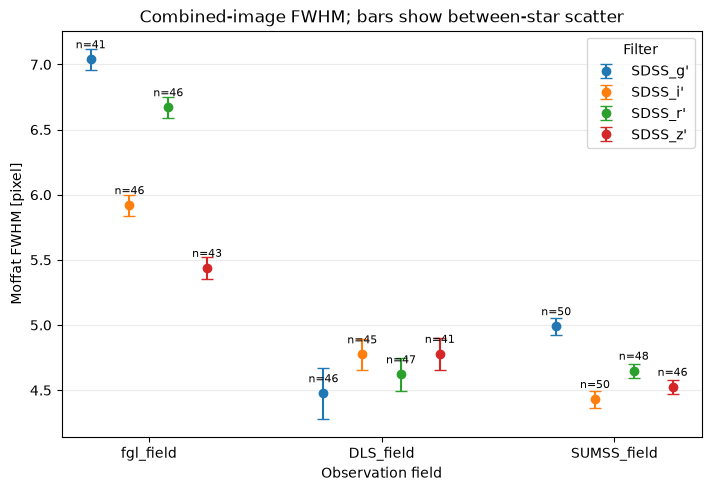

In [45]:
# Compare fields and filters; error bars show between-star scatter.
figure = fwhm_measurement.plot_fwhm()

# Photometry

## Standard Star Matching

### Load and check the standard star catalog metadata

In [46]:
# Locate the compiled standard-star catalog.
catalog_path: Path = Path(
    "/Users/yong/Desktop/Research/Photozpy/"
    "Compiled_Standard_Stars/Smith_Southern_Sky.h5"
)

# Initialize the catalog reader and load its metadata.
standard_star = StandardStarCatalog(
    catalog_path=catalog_path,
)

standard_star.print_metadata()

╒═════════════════╤═════════════════════════════════════════════════════════════════════════════════════╕
│ Field           │ Value                                                                               │
╞═════════════════╪═════════════════════════════════════════════════════════════════════════════════════╡
│ catalog_path    │ /Users/yong/Desktop/Research/Photozpy/Compiled_Standard_Stars/Smith_Southern_Sky.h5 │
├─────────────────┼─────────────────────────────────────────────────────────────────────────────────────┤
│ table_node_path │ /smith/southern/std                                                                 │
├─────────────────┼─────────────────────────────────────────────────────────────────────────────────────┤
│ table_node_name │ std                                                                                 │
├─────────────────┼─────────────────────────────────────────────────────────────────────────────────────┤
│ table_title     │ Standard Stars            

### Use one master standard star image to match the standard stars in FOV

In [47]:
# Get one Master Light from the standard field using the last telescope filter.

standard_star_field: ObservationField = DLS_field

standard_star_path = analysis_images[0].files_filtered(
    imtype="Master Light",
    field=standard_star_field.field_name,
    filter=standard_star_field.telescope.filters()[-1],
    include_path=True,
)[0]

print(f"The selected master standard star for matching is {Path(standard_star_path).name}")

The selected master standard star for matching is Master_DLS_field_SDSS_z'.fits


In [48]:
# Query catalog stars inside the standard-field image.
# Require a distance greater than 100 pixels from the image edges.
# Require catalog magnitudes <= 23 in every automatically matched filter.
# Resolve magnitude and uncertainty columns through the field's Telescope.
# Create one SourceInfo per star and attach its AB reference magnitudes.
standard_sources: Sources = standard_star.find_standard_sources(
    fits_path=standard_star_path,
    observation_field=DLS_field,
    magnitude_system="AB",
    edge_margin_pix=100.0,
    mag_limit=23.0,
)

In [49]:
# Show the number of matched standard-star candidates.
print(f"Matched standard stars: {len(standard_sources)}")

# Display all matched stars and their catalog measurements in one table.
standard_star.matched_stars

Matched standard stars: 6


,id_name,ra,ra_err,dec,dec_err,SDSS_up,SDSS_gp,SDSS_rp,SDSS_ip,SDSS_zp,SDSS_up_err,SDSS_gp_err,SDSS_rp_err,SDSS_ip_err,SDSS_zp_err,ipix,bucket,x_pix,y_pix,edge_dist_pix
3,ugriz~J105207.9-045428,163.032913,NaN,-4.907778,NaN,15.388000,14.213000,13.861,13.749,13.742,0.000970,0.000485,0.000485,0.000485,0.000728,1712126,1114,698.412080,299.716899,299.716899
6,ugriz~J105148.9-045901,162.953751,NaN,-4.983695,NaN,17.226000,15.374000,14.726,14.542,14.473,0.002138,0.000970,0.000728,0.000728,0.001213,1712123,1114,1534.078113,1094.971325,512.921887
7,ugriz~J105153.5-045702,162.973129,NaN,-4.950778,NaN,16.419001,15.424000,15.053,14.925,14.895,0.003153,0.000728,0.000485,0.000728,0.002425,1712123,1114,1328.766885,749.173830,718.233115
10,ugriz~J105221.3-045541,163.089127,NaN,-4.928083,NaN,16.931999,15.640000,15.150,14.998,14.934,0.007500,0.001455,0.001213,0.000970,0.000970,1712126,1114,109.359886,516.601989,109.359886
11,ugriz~J105154.0-050227,162.975174,NaN,-5.041083,NaN,17.344000,16.070999,15.590,15.417,15.359,0.006414,0.001213,0.001213,0.002183,0.001940,1712123,1114,1312.907864,1701.313043,345.686957
12,ugriz~J105147.9-045729,162.949875,NaN,-4.958194,NaN,17.700001,16.346001,15.754,15.509,15.384,0.004330,0.001698,0.000970,0.001455,0.001698,1712123,1114,1573.195472,826.026224,473.804528


### Generate the region files (aperture and annulus)

In [50]:
# Find the standard field's Master Lights across all available filters.
# Centroid each image independently and use its own header FWHM.
standard_regions: PhotometryRegionCollection = PhotometryRegions.generate_regions(
    image_collection=analysis_images,
    sources=standard_sources,
    root=analysis_dir,
    aperture_scaling=3.0,
    inner_annulus_scaling=5.0,
    outer_annulus_scaling=8.0,
    box_size=19,
    overwrite=True,
)

# Report the number of image/group entries prepared for review.
print(f"Standard-field review entries: {len(standard_regions)}")

Standard-field review entries: 4


In [51]:
import pandas as pd


# Display all stars, centroid outcomes, fallback reasons and region geometry.
pd.DataFrame(standard_regions.records)

,source_id,field_name,source_role,aperture_path,background_path,initial_x,initial_y,auto_x,auto_y,x,...,aperture_radius,inner_radius,outer_radius,generated_radii,accepted,reviewed,aperture_valid_fraction,annulus_valid_fraction,image_path,filter_name
0,ugriz~J105207.9-045428,DLS_field,standard,photometry/regions/DLS_field_standards/SDSS_g'...,photometry/regions/DLS_field_standards/SDSS_g'...,698.249574,299.607451,698.293132,300.248744,698.293132,...,13.427336,22.378893,35.806229,"[13.427336008601552, 22.378893347669255, 35.80...",True,False,1.0,1.0,Master_DLS_field_SDSS_g'.fits,SDSS_g'
1,ugriz~J105148.9-045901,DLS_field,standard,photometry/regions/DLS_field_standards/SDSS_g'...,photometry/regions/DLS_field_standards/SDSS_g'...,1533.961884,1094.924012,1534.902433,1096.087229,1534.902433,...,13.427336,22.378893,35.806229,"[13.427336008601552, 22.378893347669255, 35.80...",True,False,1.0,1.0,Master_DLS_field_SDSS_g'.fits,SDSS_g'
2,ugriz~J105153.5-045702,DLS_field,standard,photometry/regions/DLS_field_standards/SDSS_g'...,photometry/regions/DLS_field_standards/SDSS_g'...,1328.623450,749.114481,1328.968108,749.342790,1328.968108,...,13.427336,22.378893,35.806229,"[13.427336008601552, 22.378893347669255, 35.80...",True,False,1.0,1.0,Master_DLS_field_SDSS_g'.fits,SDSS_g'
3,ugriz~J105221.3-045541,DLS_field,standard,photometry/regions/DLS_field_standards/SDSS_g'...,photometry/regions/DLS_field_standards/SDSS_g'...,109.282292,516.450327,109.233239,516.350387,109.233239,...,13.427336,22.378893,35.806229,"[13.427336008601552, 22.378893347669255, 35.80...",True,False,1.0,1.0,Master_DLS_field_SDSS_g'.fits,SDSS_g'
4,ugriz~J105154.0-050227,DLS_field,standard,photometry/regions/DLS_field_standards/SDSS_g'...,photometry/regions/DLS_field_standards/SDSS_g'...,1312.345772,1701.343128,1313.517258,1702.707246,1313.517258,...,13.427336,22.378893,35.806229,"[13.427336008601552, 22.378893347669255, 35.80...",True,False,1.0,1.0,Master_DLS_field_SDSS_g'.fits,SDSS_g'
5,ugriz~J105147.9-045729,DLS_field,standard,photometry/regions/DLS_field_standards/SDSS_g'...,photometry/regions/DLS_field_standards/SDSS_g'...,1573.204420,825.958674,1572.892718,826.892946,1572.892718,...,13.427336,22.378893,35.806229,"[13.427336008601552, 22.378893347669255, 35.80...",True,False,1.0,1.0,Master_DLS_field_SDSS_g'.fits,SDSS_g'
6,ugriz~J105207.9-045428,DLS_field,standard,photometry/regions/DLS_field_standards/SDSS_r'...,photometry/regions/DLS_field_standards/SDSS_r'...,698.216496,299.741805,698.315481,300.398772,698.315481,...,13.863379,23.105632,36.969011,"[13.863379206874352, 23.105632011457256, 36.96...",True,False,1.0,1.0,Master_DLS_field_SDSS_r'.fits,SDSS_r'
7,ugriz~J105148.9-045901,DLS_field,standard,photometry/regions/DLS_field_standards/SDSS_r'...,photometry/regions/DLS_field_standards/SDSS_r'...,1533.917044,1095.058356,1534.878295,1096.217637,1534.878295,...,13.863379,23.105632,36.969011,"[13.863379206874352, 23.105632011457256, 36.96...",True,False,1.0,1.0,Master_DLS_field_SDSS_r'.fits,SDSS_r'
8,ugriz~J105153.5-045702,DLS_field,standard,photometry/regions/DLS_field_standards/SDSS_r'...,photometry/regions/DLS_field_standards/SDSS_r'...,1328.580936,749.239888,1328.940193,749.479444,1328.940193,...,13.863379,23.105632,36.969011,"[13.863379206874352, 23.105632011457256, 36.96...",True,False,1.0,1.0,Master_DLS_field_SDSS_r'.fits,SDSS_r'
9,ugriz~J105221.3-045541,DLS_field,standard,photometry/regions/DLS_field_standards/SDSS_r'...,photometry/regions/DLS_field_standards/SDSS_r'...,109.303888,516.583208,109.292721,516.458700,109.292721,...,13.863379,23.105632,36.969011,"[13.863379206874352, 23.105632011457256, 36.96...",True,False,1.0,1.0,Master_DLS_field_SDSS_r'.fits,SDSS_r'


In [ ]:
# Load the image with editable apertures/annuli and fixed initial-position crosses.
# Click Save & Next to validate and save the current edits.
standard_regions.review(sync_deletions=True)

## Generate Region File for Science Targets

In [53]:
# Generate regions for all science targets across their available filters.
science_regions = PhotometryRegions.generate_regions(
    image_collection=analysis_images,
    sources=sources,
    root=analysis_dir,
    aperture_scaling=3.0,
    inner_annulus_scaling=5.0,
    outer_annulus_scaling=8.0,
    box_size=25,
    overwrite=True,
)

In [54]:
# Review and save the generated regions in one DS9 session.
science_regions.review()

## Perform Photometry

In [25]:
# # reload regions if needed

# # Read the saved standard-star regions for every filter.
# # Preserve all manual positions, radii and review decisions.
# standard_regions = PhotometryRegions.load_regions(
#     image_collection=analysis_images,
#     sources=standard_sources,
#     root=analysis_dir,
# )


# # Read the saved science-target regions without regenerating them.
# science_regions = PhotometryRegions.load_regions(
#     image_collection=analysis_images,
#     sources=sources,
#     root=analysis_dir,
# )


In [55]:
# Use the existing analysis image selection.
photometry = Photometry(
    image_collection=analysis_images,
)


In [ ]:
from photozpy.photometry import LocalBackgroundOptions

# Measure all reviewed standards and science targets in one operation.
# Preserve existing reference results and update the original instrumental slots.

photometry_table = photometry.run_photometry(
    sources=(standard_sources, sources),
    regions=(standard_regions, science_regions),
    bkg_clip_sigma=3.0,
    src_detection_sigma=3.0,
    background_options=LocalBackgroundOptions(),
    verbose=False,
)

# Display all source/filter measurements in one table.
photometry_table

In [ ]:
# Inspect all available filter masks for one source in one figure.
diagnostic_row = next(
    row for row in photometry_table
    if row["status"] in ("measured", "upper_limit")
)
diagnostic_source = Sources.combine(standard_sources, sources).for_field(
    diagnostic_row["field"]
)[diagnostic_row["source_id"]]
fig = photometry.plot_background_diagnostics(diagnostic_source)


## Compute Zero Points and Calibrate Magnitudes

In [57]:
# Calculate per-filter zero points from the standard-star measurements.
# Use the original single-pass z-score clipping and unweighted average.
zero_point_table = standard_sources.calculate_zero_points(
    sigma=3.0,
)

# Show the average zero point, retained scatter, and sample counts.
# Numerical zero_point and scatter values are in magnitudes.
zero_point_table

,filter,zero_point,scatter,n_candidates,n_used,n_clipped,magnitude_system
0,SDSS_u',NaN,NaN,0,0,0,AB
1,SDSS_g',27.218948,0.008761,6,6,0,AB
2,SDSS_r',27.210099,0.015736,6,6,0,AB
3,SDSS_i',26.701795,0.017053,6,6,0,AB
4,SDSS_z',25.390310,0.033674,6,6,0,AB


In [58]:
# Retrieve individual standard-star zero points in every filter.
# Include whether each measurement was used and the exclusion reason.
standard_zero_point_table = standard_sources.zero_point_details

# Display the complete DataFrame for inspection.
standard_zero_point_table

,source_id,field,filter,reference_magnitude,instrumental_magnitude,significance,zero_point,used,reason
0,ugriz~J105207.9-045428,DLS_field,SDSS_u',15.388000,NaN,NaN,NaN,False,missing_magnitude
1,ugriz~J105207.9-045428,DLS_field,SDSS_g',14.213000,-13.007925,850.422843,27.220925,True,retained
2,ugriz~J105207.9-045428,DLS_field,SDSS_r',13.861000,-13.364460,913.001969,27.225460,True,retained
3,ugriz~J105207.9-045428,DLS_field,SDSS_i',13.749000,-12.966526,766.557869,26.715526,True,retained
4,ugriz~J105207.9-045428,DLS_field,SDSS_z',13.742000,-11.662005,314.898394,25.404005,True,retained
5,ugriz~J105148.9-045901,DLS_field,SDSS_u',17.226000,NaN,NaN,NaN,False,missing_magnitude
6,ugriz~J105148.9-045901,DLS_field,SDSS_g',15.374000,-11.857179,414.829985,27.231179,True,retained
7,ugriz~J105148.9-045901,DLS_field,SDSS_r',14.726000,-12.466525,526.532991,27.192525,True,retained
8,ugriz~J105148.9-045901,DLS_field,SDSS_i',14.542000,-12.142910,443.075566,26.684910,True,retained
9,ugriz~J105148.9-045901,DLS_field,SDSS_z',14.473000,-10.914327,174.896025,25.387326,True,retained


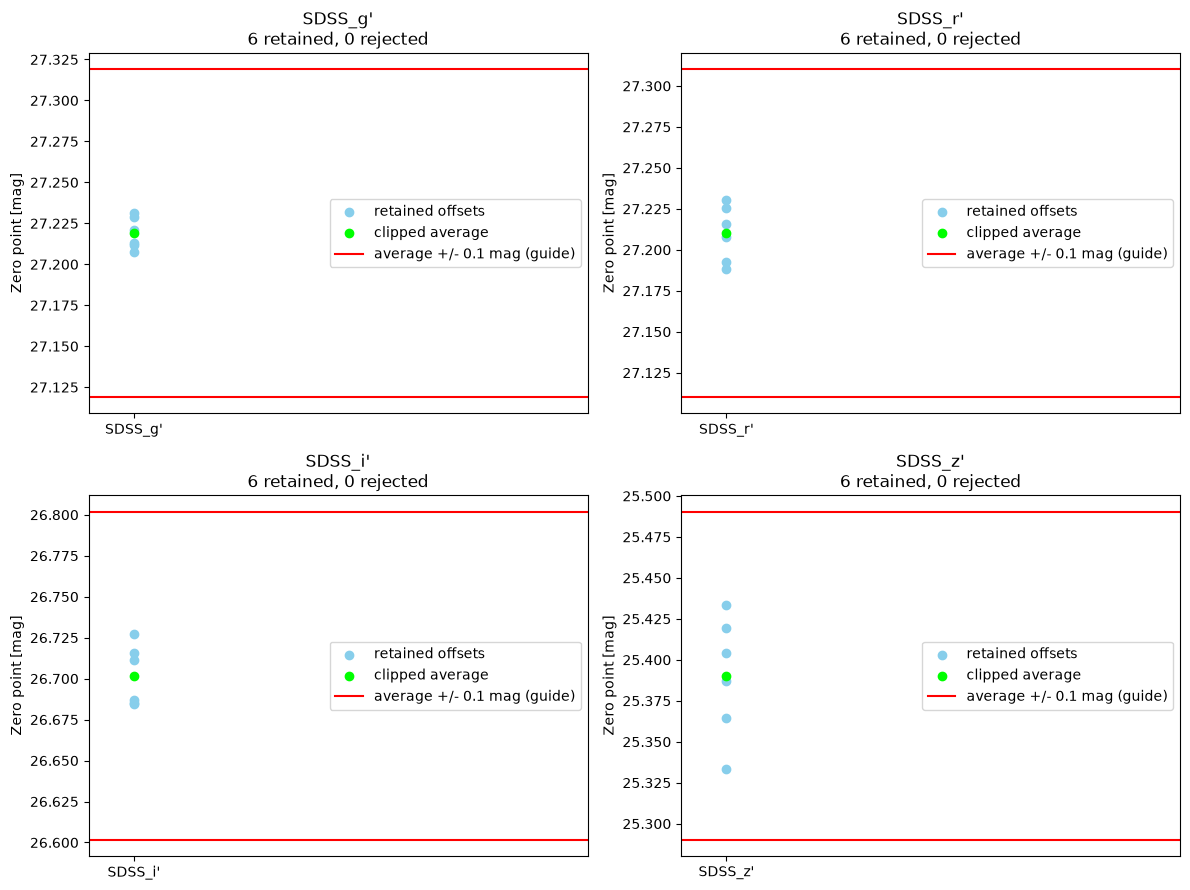

In [59]:
# Plot individual standard-star zero points and the retained average.
# Red lines mark average +/- 0.1 mag as visual guides.
zero_point_figure = standard_sources.plot_zero_point_statistics()

In [60]:
# Apply the inspected standard-star zero points to all science targets.
# Preserve instrumental errors, significance, and upper-limit flags.
calibrated_table = sources.calibrate_targets(
    standard_sources=standard_sources,
)

# Show calibrated results for every science source and filter.
#calibrated_table

In [61]:
# Display one compact filter/magnitude/error/significance summary per source.
sources.show_magnitudes(kind="calibrated")

4FGL J0746.6-4754
Field: fgl_field
Magnitude system: AB
╒══════════╤═══════════════════╤═══════════════╤════════════════╕
│ Filter   │ Magnitude (mag)   │ Error (mag)   │ Significance   │
╞══════════╪═══════════════════╪═══════════════╪════════════════╡
│ SDSS_u'  │ --                │ --            │ --             │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_g'  │ 16.9143           │ 0.0106        │ 102.10         │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_r'  │ 16.4678           │ 0.0071        │ 152.24         │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_i'  │ 16.1863           │ 0.0081        │ 133.25         │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_z'  │ 15.9873           │ 0.0183        │ 59.36          │
╘══════════╧═══════════════════╧═══════════════╧════════════════╛

SUMSS J075625-643031
Field: SUMSS_field
Magnitude system: AB
╒══════════╤════════════

In [57]:
# Display instrumental measurements for all sources.
sources.show_magnitudes(kind="instrumental")


4FGL J0746.6-4754
Field: fgl_field
Magnitude system: instrumental
╒══════════╤═══════════════════╤═══════════════╤════════════════╕
│ Filter   │ Magnitude (mag)   │ Error (mag)   │ Significance   │
╞══════════╪═══════════════════╪═══════════════╪════════════════╡
│ SDSS_u'  │ --                │ --            │ --             │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_g'  │ -10.2865          │ 0.0105        │ 103.53         │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_r'  │ -10.7323          │ 0.0072        │ 151.05         │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_i'  │ -10.5180          │ 0.0081        │ 133.26         │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_z'  │ -9.4068           │ 0.0182        │ 59.56          │
╘══════════╧═══════════════════╧═══════════════╧════════════════╛

SUMSS J075625-643031
Field: SUMSS_field
Magnitude system: instrumental
╒═══

In [58]:
# Display catalog reference magnitudes for all standard stars.
standard_sources.show_magnitudes(kind="reference")

ugriz~J105207.9-045428
Field: DLS_field
Magnitude system: AB
╒══════════╤═══════════════════╤═══════════════╤════════════════╕
│ Filter   │ Magnitude (mag)   │ Error (mag)   │ Significance   │
╞══════════╪═══════════════════╪═══════════════╪════════════════╡
│ SDSS_u'  │ 15.3880           │ 0.0010        │ --             │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_g'  │ 14.2130           │ 0.0005        │ --             │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_r'  │ 13.8610           │ 0.0005        │ --             │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_i'  │ 13.7490           │ 0.0005        │ --             │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_z'  │ 13.7420           │ 0.0007        │ --             │
╘══════════╧═══════════════════╧═══════════════╧════════════════╛

ugriz~J105148.9-045901
Field: DLS_field
Magnitude system: AB
╒══════════╤═══════